# SPH in Beltrami force field

In this tutorial, you will set up and run a pressure-less SPH example in Struphy, then inspect particle evolution with simple diagnostics.

This notebook focuses on pressure-less flow in a Beltrami force field (model `PressureLessSPH`). If you want to start from template parameter files, generate them from the command line:

```
struphy params PressureLessSPH
```

The notebook keeps everything in Python so you can adjust parameters interactively and rerun sections quickly.

## Pressure-Less Flow in a Beltrami Force Field

We begin with a particle system in a 3D box domain $\Omega \subset \mathbb{R}^3$.

Given an initial velocity field $\mathbf{u}_0(\mathbf{x})$, we seek trajectories $(\mathbf{x}_p, \mathbf{v}_p)$ for particles $p=0,\dots,N-1$ satisfying

$$
\begin{aligned}
 \dot{\mathbf x}_p &= \mathbf v_p\,,\qquad && \mathbf x_p(0) = \mathbf x_{p0}\,,
 \\[2mm]
 \dot{\mathbf v}_p &= -\nabla p(\mathbf x_p)\,,\qquad && \mathbf v_p(0) = \mathbf u_0(\mathbf x_p(0))\,.
\end{aligned}
$$

Here, $p \in H^1(\Omega)$ is a prescribed scalar field. In this example, we choose $p$ so that the force field has Beltrami structure.

In practice, the workflow is: import APIs, define geometry and time stepping, set marker loading, configure propagators, run, and visualize.

First, import the Struphy components used throughout this tutorial.

In [1]:
from struphy import (
    BoundaryParameters,
    DerhamOptions,
    EnvironmentOptions,
    LoadingParameters,
    SavingParameters,
    Simulation,
    SortingParameters,
    Time,
    WeightsParameters,
    domains,
    equils,
    grids,
)

### Step 1: Create Environment, Time Integrator, and Domain

Set up a Cartesian (cuboid) domain and use Strang splitting for time integration. These choices define the simulation skeleton before any particle data are attached.

In [2]:
# environment options
env = EnvironmentOptions()

# time stepping
time_opts = Time(dt=0.02, Tend=4, split_algo="Strang")

# geometry
l1 = -0.5
r1 = 0.5
l2 = -0.5
r2 = 0.5
l3 = 0.0
r3 = 1.0
domain = domains.Cuboid(l1=l1, r1=r1, l2=l2, r2=r2, l3=l3, r3=r3)

### Step 2: Define the Beltrami Background

Next, define velocity, pressure, and density functions for the background equilibrium. We pass these to `GenericCartesianFluidEquilibrium`, which will later be used to initialize the particle state.

In [3]:
# construct Beltrami flow
import numpy as np


def u_fun(x, y, z):
    ux = -np.cos(np.pi * x) * np.sin(np.pi * y)
    uy = np.sin(np.pi * x) * np.cos(np.pi * y)
    uz = 0 * x
    return ux, uy, uz


p_fun = lambda x, y, z: 0.5 * (np.sin(np.pi * x) ** 2 + np.sin(np.pi * y) ** 2)
n_fun = lambda x, y, z: 1.0 + 0 * x

# put the functions in a generic equilibrium container
bel_flow = equils.GenericCartesianFluidEquilibrium(u_xyz=u_fun, p_xyz=p_fun, n_xyz=n_fun)

### Step 3: Choose Grid and de Rham Options

Even for particle-based dynamics, Struphy uses spline-based projections for some fields. Here we define a tensor-product grid and matching de Rham settings.

In [4]:
# fluid equilibrium (can be used as part of initial conditions)
equil = None

# grid
grid = grids.TensorProductGrid(num_elements=(64, 64, 1))

# derham options
bcs = (("free", "free"), ("free", "free"), None)
derham_opts = DerhamOptions(degree=(3, 3, 1), bcs=bcs)

### Step 4: Instantiate the `PressureLessSPH` Simulation

Create a lightweight model instance and combine it with the environment, domain, and discretization settings from the previous steps.

In [5]:
# import model
from struphy.models import PressureLessSPH

# light-weight model instance
model = PressureLessSPH(epsilon=1.0)

sim = Simulation(
    model,
    env=env,
    time_opts=time_opts,
    domain=domain,
    equil=equil,
    grid=grid,
    derham_opts=derham_opts,
)

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/struphy/models/species.py:222: UserWarning: Override equation parameter self.epsilon =1.0
  warnings.warn(f"Override equation parameter {self.epsilon =}")


### Step 5: Configure Marker Loading and Saving

Now set particle-marker parameters. In this example we:

- load `Np=1000` particles
- keep default weight construction
- apply reflective boundaries in $x,y$ and periodic in $z$
- save all markers via `n_markers=1.0`

We also keep sorting simple with one box per direction for this first run.

In [6]:
loading_params = LoadingParameters(Np=1000)
weights_params = WeightsParameters()
boundary_params = BoundaryParameters(bc=("reflect", "reflect", "periodic"))
sorting_params = SortingParameters(boxes_per_dim=(1, 1, 1))
saving_params = SavingParameters(n_markers=1.0)

model.cold_fluid.set_markers(
    loading_params=loading_params,
    weights_params=weights_params,
    boundary_params=boundary_params,
    sorting_params=sorting_params,
    saving_params=saving_params,
)

### Step 6: Set Propagator Options

Configure the particle pushers. The key detail is to pass the Beltrami pressure potential to `push_v`, so the velocity update uses the intended force field.

In [7]:
# propagator options
from struphy import ButcherTableau

butcher = ButcherTableau(algo="forward_euler")
model.propagators.push_eta.options = model.propagators.push_eta.Options(butcher=butcher)

phi = bel_flow.p0
model.propagators.push_v.potential = phi

### Step 7: Apply Initial Conditions

Attach the Beltrami equilibrium as the background state for the cold fluid species. No additional perturbation is added in this tutorial run.

In [8]:
# background, perturbations and initial conditions
model.cold_fluid.var.add_background(bel_flow)

### Step 8: Run and Visualize

Execute the simulation pipeline in order:

1. `run()` to advance particles in time and get the post-processed `Output` object

Then plot marker trajectories to inspect how the Beltrami-driven flow evolves.

In [9]:
out = sim.run()

Time stepping:   0%|          | 0/200 [00:00<?, ?step/s]

Time stepping:   8%|▊         | 17/200 [00:00<00:01, 168.25step/s]

Time stepping:  17%|█▋        | 34/200 [00:00<00:00, 167.97step/s]

Time stepping:  26%|██▌       | 51/200 [00:00<00:00, 166.45step/s]

Time stepping:  34%|███▍      | 68/200 [00:00<00:00, 165.27step/s]

...

Time stepping:  68%|██████▊   | 136/200 [00:00<00:00, 166.32step/s]

Time stepping:  76%|███████▋  | 153/200 [00:00<00:00, 166.56step/s]

Time stepping:  85%|████████▌ | 170/200 [00:01<00:00, 166.88step/s]

Time stepping:  94%|█████████▎| 187/200 [00:01<00:00, 167.36step/s]

Time stepping: 100%|██████████| 200/200 [00:01<00:00, 166.17step/s]

In [10]:
out.info()


No post-processed data in /home/runner/work/struphy/struphy/doc/_collections/tutorials/sim_1, processing with default options (call out.pproc(...) to choose them)



Post-processing path /home/runner/work/struphy/struphy/doc/_collections/tutorials/sim_1


/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/struphy/models/species.py:222: UserWarning: Override equation parameter self.epsilon =1.0
  warnings.warn(f"Override equation parameter {self.epsilon =}")
Skipping cold_fluid.var backgrounds: Cannot restore initial-condition function: lambdas, nested functions, and closures are not supported.



No feec fields found in hdf5 file, skipping post-processing of fields.


Evaluation of 1000 marker orbits for cold_fluid


...

 72%|███████▏  | 144/201 [00:00<00:00, 231.06it/s]

 84%|████████▎ | 168/201 [00:00<00:00, 232.64it/s]

 96%|█████████▌| 192/201 [00:00<00:00, 233.77it/s]

100%|██████████| 201/201 [00:00<00:00, 233.75it/s]

Output: /home/runner/work/struphy/struphy/doc/_collections/tutorials/sim_1

Key         Description                                        Load with
----------  -------------------------------------------------  ---------
cold_fluid  marker trajectories (x, y, z, v1, v2, v3, weight)  out.evaluate('cold_fluid/orbits')
en_kin      scalar time series (en kin)                        out.evaluate('scalars', variables='en_kin')

Hints
-----
- t=-1 (index), t=slice(...) or t=0.5 (time value) selects snapshots; the t dimension is kept.
- Other keyword arguments select named coordinates, e.g. component=0 or marker=[0, 1, 2].
- Fields: pass eta1=, eta2=, eta3= (scalars or 1D arrays) to evaluate on a logical grid;
  omitted directions default to 0.5. The result carries physical coordinates X, Y, Z.
- Particles: out.info('species/variable') lists alternative datasets for dataset=.
- Orbits are an xarray.Dataset with one (t, marker) variable per quantity, e.g. orbits.x;
  each variable's 'descripti

In [11]:
print(out.cold_fluid.orbits)

<xarray.Dataset> Size: 11MB
Dimensions:    (t: 201, marker: 1000)
Coordinates:
  * t          (t) float64 2kB 0.0 0.02 0.04 0.06 0.08 ... 3.94 3.96 3.98 4.0
  * marker     (marker) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
    t_seconds  (t) float64 2kB 0.0 0.02 0.04 0.06 0.08 ... 3.94 3.96 3.98 4.0
Data variables:
    x          (t, marker) float64 2MB ...
    y          (t, marker) float64 2MB ...
    z          (t, marker) float64 2MB ...
    v1         (t, marker) float64 2MB ...
    v2         (t, marker) float64 2MB ...
    v3         (t, marker) float64 2MB ...
    weight     (t, marker) float64 2MB ...
Attributes:
    product:   orbits
    label:     marker orbits
    run:       dt=0.02, algo=Strang, Nel=(64, 64, 1), p=(3, 3, 1)
    run_name:  sim_1


i=0
i=10
i=20
i=30
i=40


i=50
i=60
i=70
i=80
i=90


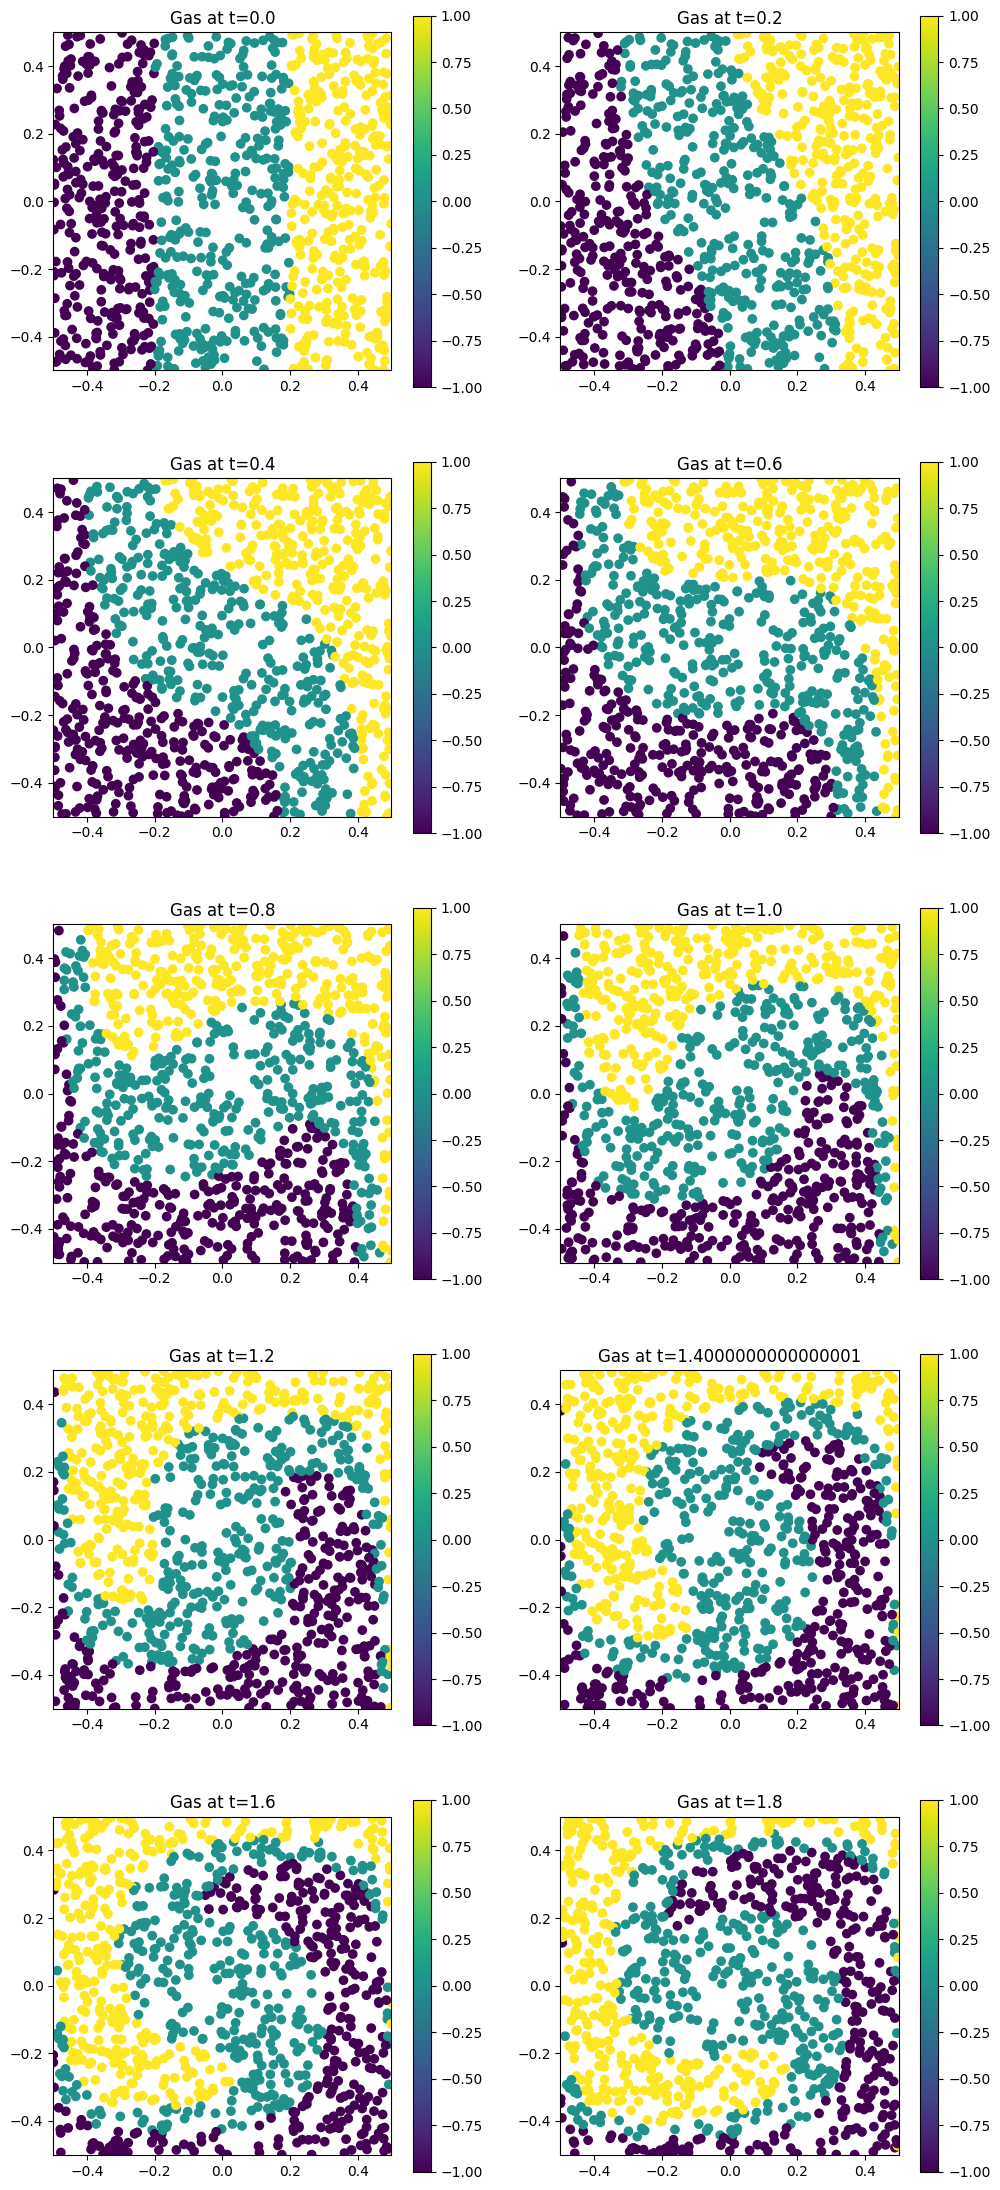

In [12]:
from matplotlib import pyplot as plt

plt.figure(figsize=(12, 28))

# one (t, marker) variable per saved quantity: orbits.x, orbits.y, ...
orbits = out.evaluate("cold_fluid/orbits")

coloring = np.select([orbits.x[0] <= -0.2, np.abs(orbits.x[0]) < +0.2, orbits.x[0] >= 0.2], [-1.0, 0.0, +1.0])

dt = time_opts.dt
Nt = out.time.size - 1
interval = Nt / 20
plot_ct = 0
for i in range(Nt):
    if i % interval == 0:
        print(f"{i=}")
        plot_ct += 1
        plt.subplot(5, 2, plot_ct)
        ax = plt.gca()
        plt.scatter(orbits.x[i], orbits.y[i], c=coloring)
        plt.axis("square")
        plt.title("n0_scatter")
        plt.xlim(l1, r1)
        plt.ylim(l2, r2)
        plt.colorbar()
        plt.title(f"Gas at t={i * dt}")
    if plot_ct == 10:
        break

### Step 9: Repeat with Structured Marker Loading

To compare loading strategies, run a second simulation in a separate folder (`sim_2`) so outputs stay isolated from the first run.

In [13]:
# light-weight model instance
model = PressureLessSPH(epsilon=1.0)

# environment options
env = EnvironmentOptions(sim_folder="sim_2")

# simulation instance
sim_tess = sim.spawn_sister(model=model, env=env)

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/struphy/models/species.py:222: UserWarning: Override equation parameter self.epsilon =1.0
  warnings.warn(f"Override equation parameter {self.epsilon =}")


This time, use tessellation-based loading so markers start on a regular grid-like pattern. This gives a useful contrast to random loading when you inspect the trajectory plots.

In [14]:
loading_params = LoadingParameters(ppb=4, loading="tesselation")
weights_params = WeightsParameters()
boundary_params = BoundaryParameters(bc=("reflect", "reflect", "periodic"))
sorting_params = SortingParameters(boxes_per_dim=(16, 16, 1))
saving_params = SavingParameters(n_markers=1.0)

model.cold_fluid.set_markers(
    loading_params=loading_params,
    weights_params=weights_params,
    boundary_params=boundary_params,
    sorting_params=sorting_params,
    saving_params=saving_params,
    bufsize=0.5,
)

In [15]:
# propagator options
from struphy import ButcherTableau

butcher = ButcherTableau(algo="forward_euler")
model.propagators.push_eta.options = model.propagators.push_eta.Options(butcher=butcher)

phi = bel_flow.p0
model.propagators.push_v.potential = phi

In [16]:
# background, perturbations and initial conditions
model.cold_fluid.var.add_background(bel_flow)

In [17]:
out_tess = sim_tess.run()

Time stepping:   0%|          | 0/200 [00:00<?, ?step/s]

Time stepping:   8%|▊         | 15/200 [00:00<00:01, 145.77step/s]

Time stepping:  15%|█▌        | 30/200 [00:00<00:01, 144.61step/s]

Time stepping:  22%|██▎       | 45/200 [00:00<00:01, 145.56step/s]

Time stepping:  30%|███       | 60/200 [00:00<00:00, 145.73step/s]

...

Time stepping:  75%|███████▌  | 150/200 [00:01<00:00, 143.99step/s]

Time stepping:  82%|████████▎ | 165/200 [00:01<00:00, 144.58step/s]

Time stepping:  90%|█████████ | 180/200 [00:01<00:00, 144.19step/s]

Time stepping:  98%|█████████▊| 195/200 [00:01<00:00, 144.85step/s]

Time stepping: 100%|██████████| 200/200 [00:01<00:00, 144.24step/s]

Skipping cold_fluid.var backgrounds: Cannot restore initial-condition function: lambdas, nested functions, and closures are not supported.



No post-processed data in /home/runner/work/struphy/struphy/doc/_collections/tutorials/sim_2, processing with default options (call out.pproc(...) to choose them)



Post-processing path /home/runner/work/struphy/struphy/doc/_collections/tutorials/sim_2



No feec fields found in hdf5 file, skipping post-processing of fields.


Evaluation of 1024 marker orbits for cold_fluid


...

i=0


i=10
i=20


i=30
i=40


i=50
i=60


i=70
i=80
i=90


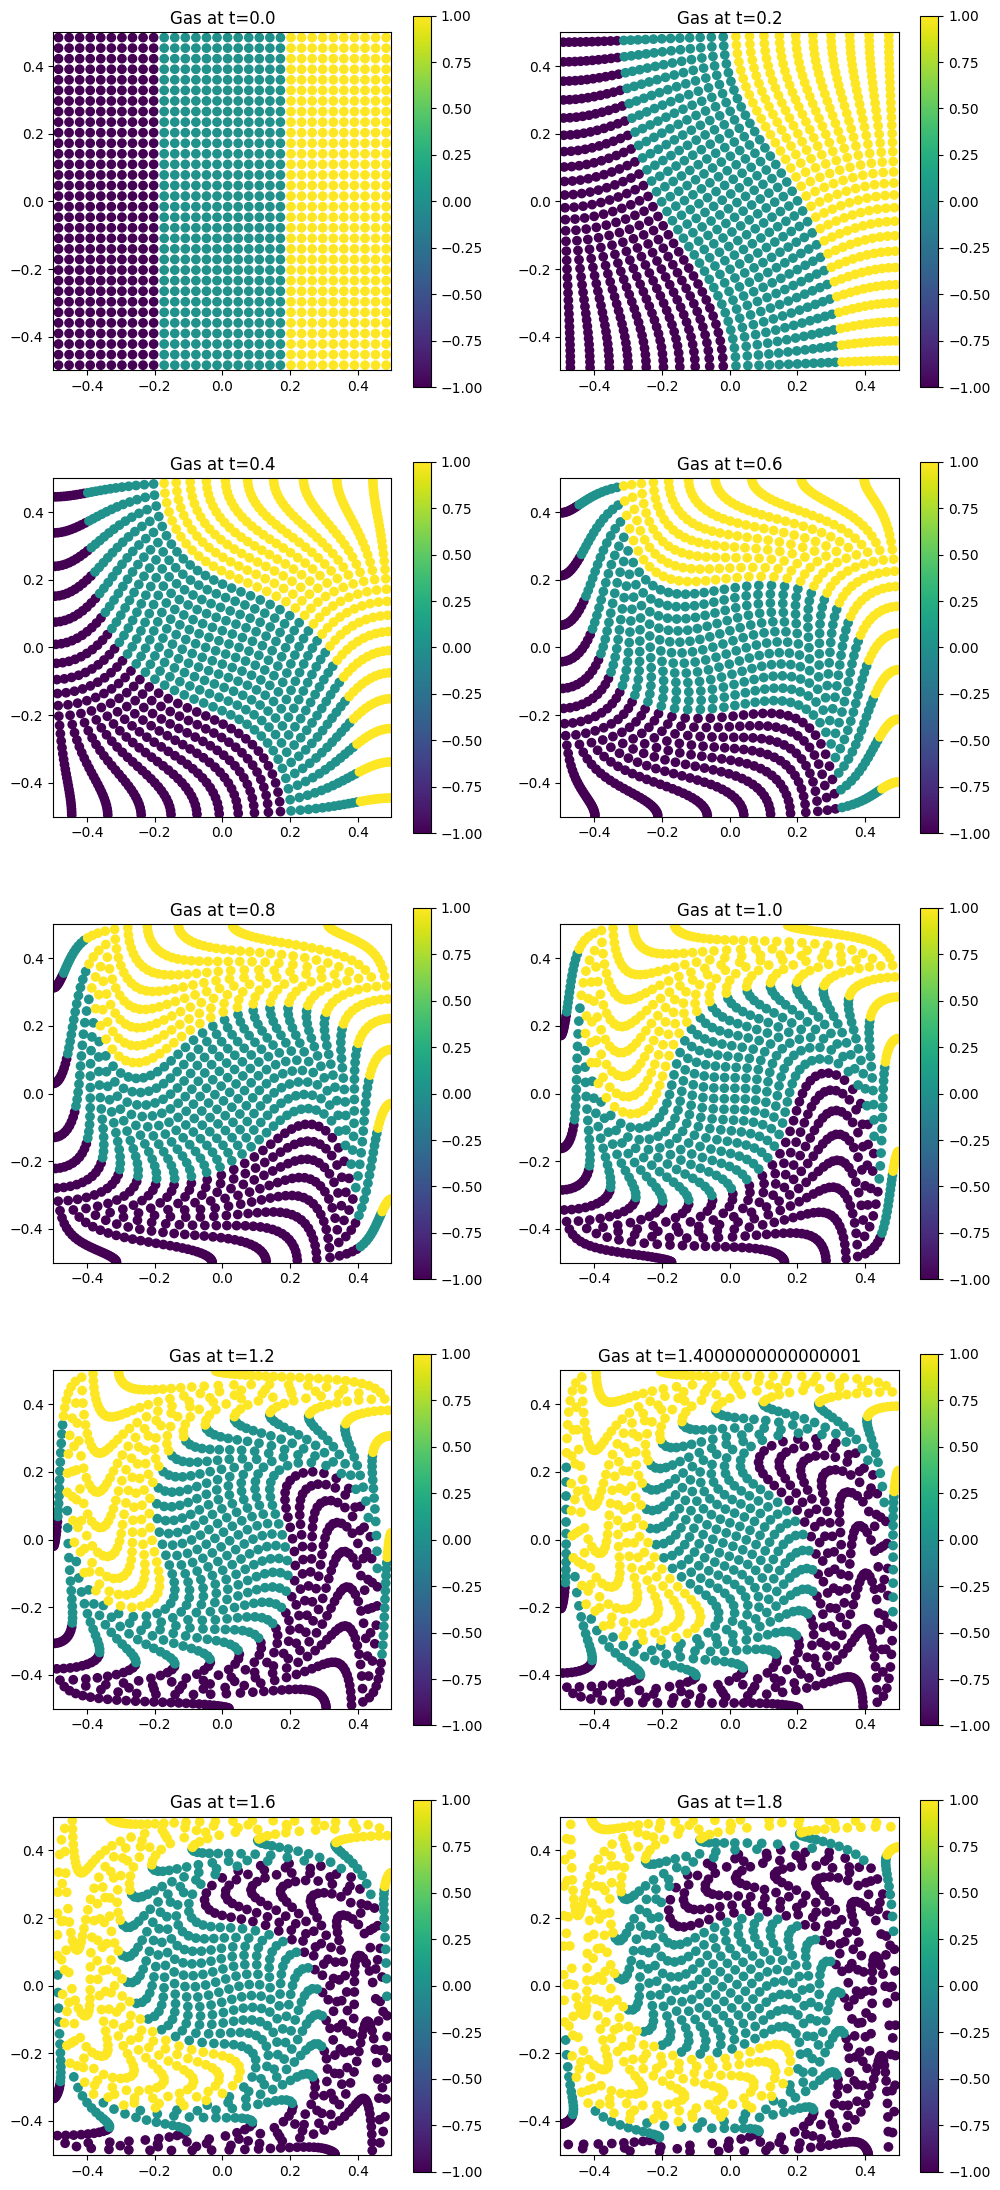

In [18]:
from matplotlib import pyplot as plt

plt.figure(figsize=(12, 28))

# one (t, marker) variable per saved quantity: orbits.x, orbits.y, ...
orbits = out_tess.evaluate("cold_fluid/orbits")

coloring = np.select([orbits.x[0] <= -0.2, np.abs(orbits.x[0]) < +0.2, orbits.x[0] >= 0.2], [-1.0, 0.0, +1.0])

dt = time_opts.dt
Nt = out_tess.time.size - 1
interval = Nt / 20
plot_ct = 0
for i in range(Nt):
    if i % interval == 0:
        print(f"{i=}")
        plot_ct += 1
        plt.subplot(5, 2, plot_ct)
        ax = plt.gca()
        plt.scatter(orbits.x[i], orbits.y[i], c=coloring)
        plt.axis("square")
        plt.title("n0_scatter")
        plt.xlim(l1, r1)
        plt.ylim(l2, r2)
        plt.colorbar()
        plt.title(f"Gas at t={i * dt}")
    if plot_ct == 10:
        break